The standardized master peptide library is the sole peptide annotation/reference file used downstream. Original annotations are retained in that file, while standardized ICTV 2025 taxonomy and protein annotations are used for analysis and plotting.

In [2]:

# 0. IMPORTS AND CONFIGURATION


import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx

from collections import defaultdict
from itertools import combinations
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import pdist
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D

sns.set_context('notebook')
sns.set_style('white')

# Input files -

Z_SL_FILE = 'z_score_df_SL_over_US_090226.csv'
Z_HBDB_FILE = 'z_hbdb_loo_results_091826.csv'
RPK_SL_FILE = './preprocessing/earliest_tp_rpk_avg_value_for_cohort_techreps_071626.csv'
RPK_HBDB_FILE = './preprocessing/hbdb_pass_100k_techreps_averaged_071626.csv'
LASV_ELISA_FILE = '../LASV_ELISA_Neut_and_PhIP_Seq_result_corrected_w_month_year_filtered_first_tp.csv'
REFERENCE_PEPTIDE_FILE = 'lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv'


# Analysis thresholds -

Z_THRESH = 3
SENS_MIN = 0.05
SPEC_MIN = 1

# Remove taxa/accessions excluded from the original downstream analysis
TAXA_TO_REMOVE = ['Konkoviridae']
ACCESSIONS_TO_REMOVE = ['WAK75154.1', 'ANT96597.1'] #accessions mapping to ampicillin resistance proteins found in vaccine constructs



## 1. Load standardized peptide reference and z-score matrices

Only the standardized master peptide library is used to supply peptide sequence, accession, ICTV species/genus/family, and standardized protein information. The z-score files provide the participant-level seroreactivity measurements.

In [3]:

# 1. LOAD INPUTS -

# Participant z-scores
df_sl_z = pd.read_csv(Z_SL_FILE).set_index('peptide')
df_hbdb_z = pd.read_csv(Z_HBDB_FILE).set_index('peptide')

# participant rpk values
df_sl_rpk = pd.read_csv(RPK_SL_FILE).set_index('peptide')
df_hbdb_rpk = pd.read_csv(RPK_HBDB_FILE).set_index('peptide')

### identify U.S. healthies with Malaria reactivity

In [4]:
df_hbdb_z_plasmodium = df_hbdb_z.filter(regex='Plasmodium', axis=0)
df_hbdb_z_plasmodium_pass = df_hbdb_z_plasmodium > 3
df_hbdb_z_plasmodium_pass.sum(axis=1)

peptide
PF3D7_0220000.1-p1|transcript=PF3D7_0220000.1|organism=Plasmodium_falciparum_3D7|gene_product=liver_stage_antigen_3|tile_1                                     2
PF3D7_0501400.1-p1|transcript=PF3D7_0501400.1|organism=Plasmodium_falciparum_3D7|gene_product=interspersed_repeat_antigen|tile_1                               2
PF3D7_0801000.1-p1|transcript=PF3D7_0801000.1|organism=Plasmodium_falciparum_3D7|gene_product=Plasmodium_exported_protein_(PHISTc)-_unknown_function|tile_1    1
dtype: int64

In [5]:
sub = df_hbdb_z_plasmodium[df_hbdb_z_plasmodium_pass]

sub.columns[sub.notna().any()].to_list()

['HBDB-001', 'HBDB-021', 'HBDB-041', 'HBDB-059', 'HBDB-084']

In [6]:
n_reactive = df_hbdb_z_plasmodium_pass.sum(axis=0)

n_peptides = df_hbdb_z_plasmodium_pass.shape[0]

print('≥1 reactive p.falciparum peptide', (n_reactive >= 1).sum())
print('≥2 reactive p.falciparum peptide', (n_reactive >= 2).sum())
print('≥3 reactive p.falciparum peptide', (n_reactive >= 3).sum())

≥1 reactive p.falciparum peptide 5
≥2 reactive p.falciparum peptide 0
≥3 reactive p.falciparum peptide 0


## identify SL with Malaria reactivity

In [7]:
df_sl_z_plasmodium = df_sl_z.filter(regex='Plasmodium', axis=0)
df_sl_z_plasmodium_pass = df_sl_z_plasmodium > 3
df_sl_z_plasmodium_pass.sum(axis=1)

peptide
PF3D7_0220000.1-p1|transcript=PF3D7_0220000.1|organism=Plasmodium_falciparum_3D7|gene_product=liver_stage_antigen_3|tile_1                                     330
PF3D7_0501400.1-p1|transcript=PF3D7_0501400.1|organism=Plasmodium_falciparum_3D7|gene_product=interspersed_repeat_antigen|tile_1                               388
PF3D7_0801000.1-p1|transcript=PF3D7_0801000.1|organism=Plasmodium_falciparum_3D7|gene_product=Plasmodium_exported_protein_(PHISTc)-_unknown_function|tile_1    346
dtype: int64

In [8]:
n_reactive = df_sl_z_plasmodium_pass.sum(axis=0)

n_peptides = df_sl_z_plasmodium_pass.shape[0]

print('≥1 reactive p.falciparum peptide', (n_reactive >= 1).sum())
print('≥2 reactive p.falciparum peptide', (n_reactive >= 2).sum())
print('≥3 reactive p.falciparum peptide', (n_reactive >= 3).sum())

≥1 reactive p.falciparum peptide 395
≥2 reactive p.falciparum peptide 377
≥3 reactive p.falciparum peptide 292


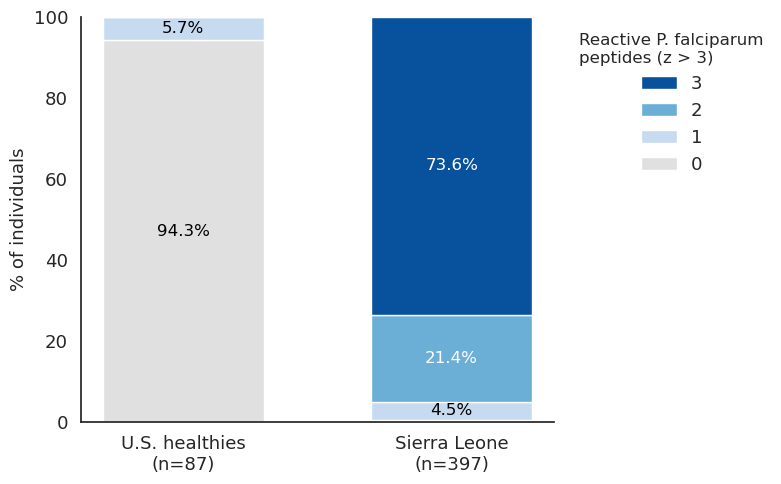

In [41]:
counts = pd.DataFrame({
    'U.S. healthies': df_hbdb_z_plasmodium_pass.sum(axis=0).value_counts(), "Sierra Leone": df_sl_z_plasmodium_pass.sum(axis=0).value_counts(), 
}).reindex(range(4), fill_value=0).fillna(0) #reindex(range(4)) forces the rows to be exactly 0, 1, 2 and 3. fills any missing category with 0.

pct = 100*counts / counts.sum()


colors = ["#e0e0e0", "#c6dbef", "#6baed6", "#08519c"]  # 0 = grey, then light → dark blue
labels = ["0", "1", "2", "3"]
width = 0.6

fig, ax = plt.subplots(figsize=(8, 5))

bottom = pd.Series(0, index=pct.columns)

for k, c, lab in zip(pct.index, colors, labels):
    ax.bar(pct.columns, pct.loc[k], bottom=bottom, color=c, label=lab,
           width=width, edgecolor="white", linewidth=1)

    for i, col in enumerate(pct.columns):
        v = pct.loc[k, col]
        if v == 0 or v <= 1:
            continue
        ax.text(i, bottom[col] + v / 2, f"{v:.1f}%", ha="center", va="center",
                fontsize=12, color="white" if k >= 2 else "black")

    bottom += pct.loc[k]


# n under each cohort label
ax.set_xticks(range(len(pct.columns)))
ax.set_xticklabels([f"{col}\n(n={int(counts[col].sum())})" for col in pct.columns], fontsize=13)

ax.set_ylabel("% of individuals", fontsize=13)
ax.set_ylim(0, 100)

ax.tick_params(axis="y", labelsize=13)

ax.legend(title="Reactive P. falciparum\npeptides (z > 3)", bbox_to_anchor=(1.02, 1),
          loc="upper left", frameon=False, reverse=True, fontsize=13)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig('pfalciparum_peps_hbdb_vs_sl.svg', format='svg')
plt.show()

### 2. Define the filtered high-specificity peptide set

A peptide is considered reactive when its participant-level z-score is >3. Peptides retained for the downstream viral analysis have ≥5% sensitivity in the SL cohort and ≥100% specificity in HBDB, followed by the same exclusion of non-target taxa/artificial-vector accessions used previously.

In [9]:

# 2. PEPTIDE-LEVEL FILTERING -


pass_sl = df_sl_z > Z_THRESH
pass_hbdb = df_hbdb_z > Z_THRESH

peptide_stats = pd.DataFrame({
    'sensitivity': pass_sl.mean(axis=1),
    'specificity': 1 - pass_hbdb.mean(axis=1)
})


hits = peptide_stats[
    (peptide_stats['sensitivity'] >= SENS_MIN) &
    (peptide_stats['specificity'] >= SPEC_MIN)
].copy()

hits = pd.DataFrame(hits).reset_index('peptide')

print(hits.peptide.nunique(), 'before exclusion of taxa and accessions')


1292 before exclusion of taxa and accessions


In [10]:
peps_metadata = pd.read_csv(REFERENCE_PEPTIDE_FILE)
peps_metadata.rename(columns={'seq_id':'peptide'}, inplace=True)

In [11]:
hits = hits.merge(peps_metadata, on='peptide', how='left')

In [ ]:
hits.to_csv('pep_hits_091826.csv')

In [13]:

# Original analysis exclusions
hits = hits[
    ~hits['family'].isin(TAXA_TO_REMOVE)
].copy()

hits = hits[
    ~hits['accession'].isin(ACCESSIONS_TO_REMOVE)
].copy()


print(f'Filtered peptide hits: {hits.peptide.nunique()}')
print(f'Unique standardized species: {hits.species.nunique()}')
print(f'Unique standardized genera: {hits.genus.nunique()}')
print(f'Unique standardized families: {hits.family.nunique()}')

Filtered peptide hits: 1287
Unique standardized species: 367
Unique standardized genera: 43
Unique standardized families: 10


In [ ]:
hits.to_csv('pep_hits_wo_taxa_to_remove_091826.csv')

In [15]:
print(hits.shape)

(1287, 21)


In [16]:
hits['family'].unique()

array(['Hantaviridae', 'Phenuiviridae', 'Arenaviridae', 'Filoviridae',
       'Flaviviridae', 'Togaviridae', 'Paramyxoviridae', 'Nairoviridae',
       'Matonaviridae', 'Trypanosomatidae'], dtype=object)

## convert data to long format and add z score and RPK score to the peptide hits

In [17]:

# 3. LONG-FORM PARTICIPANT DATA -

df_z = pd.concat([df_sl_z, df_hbdb_z], axis=1)
df_rpk = pd.concat([df_sl_rpk, df_hbdb_rpk], axis=1)

z_long = (
    df_z.loc[hits['peptide']]
    .reset_index()
    .melt(
        id_vars='peptide',
        var_name='individual',
        value_name='z_score'
    )
)

rpk_long = (
    df_rpk.loc[hits['peptide']]
    .reset_index()
    .melt(
        id_vars='peptide', 
        var_name='individual', 
        value_name='rpk'
    )
)

long = z_long.merge(
    rpk_long, 
    on=['peptide', 'individual'], 
    how='left'
)


long = long.merge(
    hits[
        [
            'peptide', 'sequence', 'species', 'genus', 'family',
            'protein_std', 'accession'
        ]
    ].drop_duplicates('peptide'),
    on='peptide',
    how='left'
)

long['cohort'] = np.where(
    z_long['individual'].str.startswith('HBDB-'),
    'HBDB',
    'SL'
)

long['category'] = np.select(
    [
        long['individual'].str.startswith('S-'),
        long['individual'].str.startswith('C-'),
        long['individual'].str.startswith('HBDB-')
    ],
    [
        'Lassa survivor',
        'Household contact',
        'US healthy'
    ],
    default='Unknown'
)

long['reactive'] = long['z_score'] > Z_THRESH


print(long['category'].nunique())

3


In [18]:
long.to_csv('long.csv', index=False)

## fraction of total peptides in the library being enriched

In [19]:
lassa = long.loc[long['species'] == 'Mammarenavirus lassaense']

perc_lasv = lassa['peptide'].nunique() / peps_metadata.loc[peps_metadata['species'] == 'Mammarenavirus lassaense'].shape[0] * 100

print(round(perc_lasv, 2))

1.69


In [20]:
lassa = long.loc[long['species'] == 'Plasmodium falciparum']

perc_lasv = lassa['peptide'].nunique() / peps_metadata.loc[peps_metadata['species'] == 'Mammarenavirus lassaense'].shape[0] * 100

print(round(perc_lasv, 2))

0.0
